# Proyecto 2: plantilla de entrega

Entrega: **viernes 16 de octubre** · 10 puntos

Las secciones ya están creadas y las celdas de código vacías. Trabajen sobre este archivo, renómbrenlo `P2_ApellidoNombre.ipynb` y borren las instrucciones en *cursiva* antes de entregar. Pueden reutilizar el dataset del Proyecto 1 o elegir uno nuevo.

| Criterio | Pts | Qué buscamos |
|---|---|---|
| Preparación y validación | 3 | El test se toca una sola vez; nada se filtra al modelo |
| Búsqueda de opciones y ensamble | 2 | Probaron opciones con razón, no al azar |
| Métrica e interpretación | 2 | Dicen por qué esa métrica y dónde se equivoca el modelo |
| Análisis sin respuestas | 2 | Cada grupo o eje tiene nombre y descripción |
| Límites | 1 | Qué no se puede concluir |

## 1. Pregunta y datos

**Qué se quiere responder, para quién, y qué decisión cambiaría según la respuesta. Si vienen del Proyecto 1, digan qué van a hacer distinto:**
 Queremos saber si las características de audio, como ritmo, energía o acústica, concuerdan con las etiquetas de género del dataset. Esto puede ayudar a alguien que organiza un catálogo musical a poner una primera etiqueta a canciones nuevas y a decidir cuáles conviene revisar un poco más. Un desacuerdo no significa que la canción esté mal etiquetada sino que una canción puede combinar estilos y esas medidas no describen todo lo que escuchamos.

**Pregunta:** ¿Hasta qué punto las características del audio hacen match con las etiquetas de género que les asignaron en el dataset y con qué canciones hay más desacuerdo?

**Tipo de problema:** Clasificación, pues hay que predecir una categoría de género. Se usarán cinco géneros con suficientes canciones: acoustic, classical, electronic, hip-hop y rock. Además, agruparemos canciones por sus características de audio sin usar la etiqueta de género para describir los perfiles donde aparecen más desacuerdos.

**Columna que se quiere predecir:** track_genre, la etiqueta de género que viene en el dataset.

**Fuente, fecha de descarga y licencia:** Spotify Tracks Dataset, publicado por Maharshi Pandya en Hugging Face: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset. Los datos se recopilaron con la API de Spotify y muestra una licencia BSD. Fecha de descarga: 16-10-2026.

**Qué representa una fila:** Un registro de una pista musical, con su etiqueta de género, datos de identificación y medidas de audio. 

**Qué haremos distinto del Proyecto 1:** Este dataset es más grande en comparación con los 144 partidos del proyecto anterior. Aquí voy a comparar varios modelos y estudiar sus desacuerdos por perfiles de audio.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_STATE = 42

# No cargaba con la ruta de pandas, así que la cambié a Path
ruta_datos = Path("spotify_tracks_dataset.csv")
if not ruta_datos.exists():
    ruta_datos = Path("Proyecto2") / ruta_datos

df = pd.read_csv(ruta_datos)
print("Dataset cargado:", df.shape)
df.head()


Dataset cargado: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Mirada rápida a los datos

*Lo justo para entender el dataset y decidir cómo prepararlo: tamaño, huecos, qué tan balanceada está la columna a predecir, y dos o tres relaciones que importen. No repitan el análisis del Proyecto 1.*

Tamaño del archivo: (114000, 21)
Géneros distintos: 114
Columnas con más valores faltantes:
artists       1
album_name    1
track_name    1
Unnamed: 0    0
mode          0
dtype: int64

Canciones por género antes de limpiar:
track_genre
acoustic      1000
classical     1000
electronic    1000
hip-hop       1000
rock          1000
Name: count, dtype: int64

Canciones por género después de limpiar:
track_genre
electronic    927
acoustic      898
classical     694
hip-hop       644
rock          412
Name: count, dtype: int64
Tamaño final: (3575, 21)
Valores faltantes en las canciones elegidas: 0

Medianas por género:
             energy  acousticness  danceability
track_genre                                    
acoustic      0.389         0.699         0.556
classical     0.144         0.972         0.380
electronic    0.716         0.063         0.667
hip-hop       0.698         0.174         0.726
rock          0.712         0.086         0.564


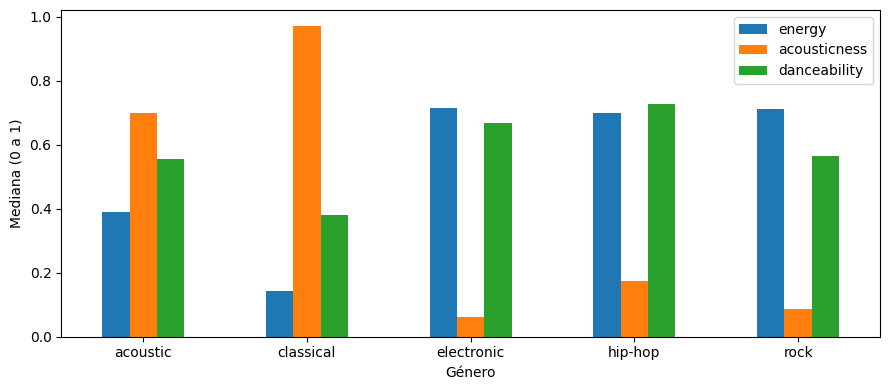

In [ ]:
print("Tamaño del archivo:", df.shape)
print("Géneros distintos:", df["track_genre"].nunique())
print("Columnas con más valores faltantes:")
print(df.isna().sum().sort_values(ascending=False).head())

generos = ["acoustic", "classical", "electronic", "hip-hop", "rock"]
datos = df[df["track_genre"].isin(generos)].copy()
print("\nCanciones por género antes de limpiar:")
print(datos["track_genre"].value_counts())

# Una canción puede repetirse con el mismo ID o con otro ID y el mismo nombre
# Por eso quité todos esos casos para evitar que aparezca en entrenamiento y la prueba
datos["cancion"] = (datos["artists"].str.lower().str.strip() + " - " +
                    datos["track_name"].str.lower().str.strip())
datos = datos[~datos.duplicated("track_id", keep=False)]
datos = datos[~datos.duplicated("cancion", keep=False)]
datos = datos.drop(columns="cancion")

print("\nCanciones por género después de limpiar:")
print(datos["track_genre"].value_counts())
print("Tamaño final:", datos.shape)
print("Valores faltantes en las canciones elegidas:", datos.isna().sum().sum())

# Comparo tres características que sí describen el audio.
medianas = datos.groupby("track_genre")[["energy", "acousticness", "danceability"]].median()
print("\nMedianas por género:")
print(medianas.round(3))
medianas.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Mediana (0 a 1)")
plt.xlabel("Género")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Lo que importa de este dataset para modelar:**

1. El archivo tiene 114,000 registros y 114 géneros. Elegí cinco géneros conocidos, con 1,000 registros cada uno antes de limpiar. Después de quitar las canciones repetidas quedaron 3,575 registros, el género más pequeño tiene 412 y el más grande tiene 927.
2. Quité todas las canciones que aparecían más de una vez por ID o por artista y título. Así evito que una misma canción quede tanto en entrenamiento como en prueba. 
3. Las medianas muestran diferencias, pues "classical" tiene energía de 0.144 y acústica de 0.972, mientras "electronic" tiene 0.716 y 0.063. "hip-hop" tiene la mayor mediana de bailabilidad con 0.726. 

## 3. Separar y preparar

*Separen primero. Todo lo que se calcule a partir de los datos (escalas, codificaciones, rellenos de huecos) va **dentro** del `Pipeline`, para que se calcule solo con los datos de entrenamiento. Si los datos tienen fechas, no los barajen: corten por fecha.*

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# Uso solo medidas numéricas de audio
columnas = [
    "duration_ms", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
]
X = datos[columnas]
y = datos["track_genre"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Entrenamiento:", X_tr.shape, "| Prueba reservada:", X_te.shape)
print(y_tr.value_counts())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (2860, 10) | Prueba reservada: (715, 10)
track_genre
electronic    742
acoustic      718
classical     555
hip-hop       515
rock          330
Name: count, dtype: int64


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# El escalador se ajustará dentro de cada Pipeline, nunca antes de separar.
preparacion = StandardScaler()

**Por qué se preparó así:** Solo uso medidas numéricas del audio. No uso nombres, ID, popularidad ni códigos musicales como `key` o `mode` para predecir. En estas canciones no hay huecos que rellenar. Escalo las medidas dentro del pipeline para que una columna como duración, que usa números grandes, no tenga más peso solo por su unidad. En cada pliegue el escalador aprende únicamente de las canciones de entrenamiento.

## 4. Modelos de comparación

*Dos puntos de comparación obligatorios: el modelo tonto (siempre el promedio, o siempre la categoría más común) y un modelo simple. Sin ellos, el número del ensamble no significa nada.*


In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

modelo_tonto = DummyClassifier(strategy="most_frequent")
puntajes_tonto = cross_val_score(
    modelo_tonto, X_tr, y_tr, cv=cv, scoring="f1_macro"
)
print("Modelo tonto, F1 macro en validación:",
      round(puntajes_tonto.mean(), 3),
      "+/-", round(puntajes_tonto.std(), 3))

Modelo tonto, F1 macro en validación: 0.082 +/- 0.0


In [17]:
from sklearn.tree import DecisionTreeClassifier

modelo_simple = Pipeline([
    ("prep", preparacion),
    ("modelo", DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE
    )),
])
puntajes_simple = cross_val_score(
    modelo_simple, X_tr, y_tr, cv=cv, scoring="f1_macro"
)
print("Árbol pequeño, F1 macro en validación:",
      round(puntajes_simple.mean(), 3),
      "+/-", round(puntajes_simple.std(), 3))


Árbol pequeño, F1 macro en validación: 0.529 +/- 0.024


**Métrica elegida y por qué:** Usaré F1 macro. Calcula una medida de aciertos y errores para cada género y luego les da el mismo peso. Me interesa que el modelo no funcione bien solo con algunos géneros mientras confunde mucho a los demás. Además del número general, en la evaluación final revisaré cuáles etiquetas se confunden y en qué perfiles de canciones pasa más.

## 5. Ensamble y búsqueda de opciones

*Al menos un ensamble (bosque o boosting). El `Pipeline` completo va dentro del buscador, para que cada vuelta de la validación prepare los datos de nuevo. Digan qué opciones probaron, en qué rango y por qué.*

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("prep", preparacion),
    ("modelo", RandomForestClassifier(random_state=RANDOM_STATE)),
])

opciones = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [12, None],
    "modelo__min_samples_leaf": [1, 3],
}

busqueda = GridSearchCV(pipe, opciones, scoring="f1_macro", cv=cv)
busqueda.fit(X_tr, y_tr)

print("Combinaciones probadas:", len(busqueda.cv_results_["params"]))
print("Mejores parámetros:", busqueda.best_params_)
print("Mejor F1 macro en validación:", round(busqueda.best_score_, 3))

Combinaciones probadas: 8
Mejores parámetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
Mejor F1 macro en validación: 0.654


**Qué se probó y por qué ese rango:** Probé 8 combinaciones: 100 o 200 árboles; profundidad máxima de 12 o sin límite; y hojas de al menos 1 o 3 canciones. Es una búsqueda pequeña para ver si un bosque más grande o menos limitado mejora el resultado. Todas las opciones usan los mismos cinco pliegues y la misma métrica.

**Mejor combinación y su puntaje en validación:** La mejor opción fue un bosque de 100 árboles, profundidad máxima de 12 y un mínimo de 1 canción por hoja. Obtuvo **0.654 de F1 macro** en validación. El árbol pequeño obtuvo **0.529** y el modelo que siempre elige el género más común, **0.082**. La prueba final sigue reservada para la sección 6.


## 6. Evaluación final

*Aquí, y solo aquí, se toca el test. Una vez. Después de esta celda no se ajusta nada.*

In [19]:
from sklearn.metrics import f1_score

# Ajusto los dos modelos de comparación con todo el entrenamiento.
modelo_tonto.fit(X_tr, y_tr)
modelo_simple.fit(X_tr, y_tr)

# Las tres predicciones sobre la prueba se hacen aquí, una vez.
pred_tonto = modelo_tonto.predict(X_te)
pred_simple = modelo_simple.predict(X_te)
pred_bosque = busqueda.predict(X_te)

comparacion = pd.DataFrame({
    "Modelo": ["Tonto", "Árbol pequeño", "Bosque"],
    "F1 macro validación": [puntajes_tonto.mean(), puntajes_simple.mean(),
                            busqueda.best_score_],
    "F1 macro prueba": [f1_score(y_te, pred_tonto, average="macro"),
                        f1_score(y_te, pred_simple, average="macro"),
                        f1_score(y_te, pred_bosque, average="macro")],
})
print(comparacion.round(3))

# Guardamos las respuestas para estudiar los desacuerdos sin volver a predecir.
evaluacion = pd.DataFrame({
    "real": y_te,
    "predicho": pred_bosque,
}, index=y_te.index)
evaluacion["desacuerdo"] = evaluacion["real"] != evaluacion["predicho"]

print("\nGénero del dataset (filas) frente a predicción del bosque (columnas):")
print(pd.crosstab(evaluacion["real"], evaluacion["predicho"]))

          Modelo  F1 macro validación  F1 macro prueba
0          Tonto                0.082            0.082
1  Árbol pequeño                0.529            0.527
2         Bosque                0.654            0.623

Género del dataset (filas) frente a predicción del bosque (columnas):
predicho    acoustic  classical  electronic  hip-hop  rock
real                                                      
acoustic         131          8          17        8    16
classical         12        123           1        2     1
electronic        19          4         133       24     5
hip-hop           18          0          23       85     3
rock              33          0          28        9    12


**Comparación contra los modelos de comparación:**

| Modelo | F1 macro (validación) | F1 macro (prueba) |
|---|---:|---:|
| Tonto | 0.082 | 0.082 |
| Árbol pequeño | 0.529 | 0.527 |
| Bosque | 0.654 | 0.623 |

El bosque obtuvo el mejor resultado de los tres. En prueba bajó un poco respecto a la validación, así que conviene reportar el 0.623 como resultado final. F1 macro no es el porcentaje de canciones acertadas: resume qué tan bien se clasificó cada género y les da el mismo peso.

**Dónde falla el modelo:** La mayor dificultad está en `rock`. De 82 canciones de prueba con esa etiqueta, el bosque coincidió en 12; clasificó 33 como `acoustic` y 28 como `electronic`. En cambio, coincidió con 123 de las 139 canciones `classical`. Esto muestra que las medidas de audio distinguen mejor unos géneros que otros. Un desacuerdo con la etiqueta del archivo no demuestra que la canción esté mal etiquetada.


## 7. Análisis sin respuestas

*Elijan **una** ruta. Escalar es obligatorio en ambas.*

- **Ruta A, agrupar**: k-Means, jerárquico o DBSCAN. Justifiquen el número de grupos (silhouette **y** sentido para el negocio) y describan cada grupo.
- **Ruta B, resumir columnas**: PCA (t-SNE solo para mirar). Cuánta información conservan los ejes y qué columnas pesan en los primeros dos.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

columnas_grupos = ["energy", "acousticness", "danceability",
                   "instrumentalness", "speechiness"]
escalador_grupos = StandardScaler()
Z_tr = escalador_grupos.fit_transform(X_tr[columnas_grupos])

# Silhouette más alto significa grupos más separados.
for k in [2, 3, 4]:
    candidato = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    grupos_candidato = candidato.fit_predict(Z_tr)
    puntaje = silhouette_score(Z_tr, grupos_candidato)
    print(k, "grupos: silhouette =", round(puntaje, 3))

# Con cuatro grupos se distinguen perfiles que se pueden describir.
km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
grupo_tr = km.fit_predict(Z_tr)
perfil = X_tr[columnas_grupos].copy()
perfil["grupo"] = grupo_tr

resumen_grupos = perfil.groupby("grupo")[columnas_grupos].mean().round(2)
resumen_grupos["canciones"] = perfil.groupby("grupo").size()
print("\nPromedios y tamaños de cada grupo:")
print(resumen_grupos)

**Interpretación:** El puntaje silhouette fue **0.370** con 2 grupos, **0.373** con 3 y **0.385** con 4. Elegí 4 porque fue el mayor de los tres y permite describir perfiles distintos. La diferencia entre puntajes es pequeña, así que los grupos no están completamente separados.

| Grupo | Nombre sencillo | Qué lo caracteriza en entrenamiento | Canciones |
|---|---|---|---:|
| 0 | Enérgicas y con más voz hablada | Energía 0.71, bailabilidad 0.71 y la mayor presencia de voz hablada (0.29). | 259 |
| 1 | Enérgicas y poco acústicas | Energía 0.73 y acústica 0.13. Es el grupo más grande. | 1,379 |
| 2 | Suaves, acústicas e instrumentales | Energía 0.16, acústica 0.93 e instrumentalidad 0.85. | 415 |
| 3 | Suaves y acústicas | Energía 0.34 y acústica 0.75, con poca instrumentalidad. | 807 |

Los nombres resumen promedios del grupo; no describen necesariamente a cada canción por separado.


## 8. Conexión entre las dos partes

*Lo que distingue un buen Proyecto 2 de dos tareas pegadas. Por ejemplo: ¿el modelo se equivoca más en algún grupo? ¿Los ejes de PCA coinciden con las columnas más importantes del modelo? ¿Los grupos sugieren una columna nueva?*

In [21]:
# Uso el escalador y los grupos ya definidos con entrenamiento.
Z_te = escalador_grupos.transform(X_te[columnas_grupos])
evaluacion["grupo"] = km.predict(Z_te)

cruce = evaluacion.groupby("grupo")["desacuerdo"].agg(["sum", "count", "mean"])
cruce.columns = ["desacuerdos", "canciones", "proporción"]
print("Desacuerdos del bosque por grupo:")
print(cruce.round(3))

print("\nGéneros del dataset presentes en cada grupo:")
print(pd.crosstab(evaluacion["grupo"], evaluacion["real"]))

Desacuerdos del bosque por grupo:
       desacuerdos  canciones  proporción
grupo                                    
0               13         64       0.203
1              144        339       0.425
2                8        107       0.075
3               66        205       0.322

Géneros del dataset presentes en cada grupo:
real   acoustic  classical  electronic  hip-hop  rock
grupo                                                
0             1          1          18       42     2
1            57          4         145       73    60
2             6         95           6        0     0
3           116         39          16       14    20


**Lo que aprendimos al cruzar ambas partes:** El grupo 1, de canciones enérgicas y poco acústicas, tuvo **144 desacuerdos entre 339 canciones de prueba (42.5 %)**. Fue la proporción más alta. En el grupo 2, de canciones suaves, acústicas e instrumentales, hubo **8 desacuerdos entre 107 (7.5 %)**. Por tanto, el modelo coincide menos con las etiquetas en ciertos perfiles de audio.

El grupo 1 contiene canciones de varios géneros, entre ellos `electronic`, `hip-hop` y `rock`; esta mezcla puede ayudar a entender por qué hay más confusiones. El grupo 2 contiene sobre todo canciones `classical`, que el modelo distinguió mejor. No podemos decir que la energía cause los desacuerdos: también cambia la mezcla de géneros entre grupos. Estos números señalan qué canciones convendría revisar con más atención al organizar un catálogo.


## 9. Conclusiones y límites

*Tres párrafos cortos:*

1. *La respuesta a la pregunta de la sección 1, con su número y qué tan seguro es.*
2. *Qué **no** se puede concluir: sesgos del dataset, poblaciones que no aparecen, causas que no se pueden afirmar.*
3. *Qué haría falta para mejorarlo.*

## 10. Lista antes de entregar

- [ ] ¿Todo lo que se calcula con los datos está **dentro** del `Pipeline`, y el `Pipeline` dentro de la validación?
- [ ] ¿Está escrito **por qué** esa métrica?
- [ ] ¿Hay modelo tonto y modelo simple para comparar?
- [ ] ¿La búsqueda de opciones dice qué, en qué rango y por qué?
- [ ] ¿Cada grupo tiene nombre y descripción en palabras del negocio?
- [ ] ¿El test se tocó una sola vez?
- [ ] ¿Hay un párrafo de lo que **no** se puede concluir?
- [ ] ¿El notebook corre de arriba a abajo sin errores (`Restart & Run All`)?
- [ ] ¿Incluye la bitácora de colaboración si usaron AI?

**Entrega: viernes 16 de octubre.** Parcial II: jueves 22 de octubre (sesiones 11 a 21).